In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Q2. Multiclass boosting from scratch

# (Q-2).a

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.tree import DecisionTreeClassifier
import os
from sklearn.datasets import fetch_olivetti_faces
from pathlib import Path


In [6]:
# create a 3-class dataset

X = np.array([
    [1, 2],
    [2, 1],
    [3, 2],
    [6, 5],
    [7, 6],
    [8, 5]
])

y_true = np.array([0, 0, 1, 1, 2, 2])

y_pred = np.array([0, 1, 1, 1, 0, 2])

n_samples = len(y_true)
K = len(np.unique(y_true))

weights = np.ones(n_samples) / n_samples

print("Initial sample wts : ", weights)

Initial sample wts :  [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]


In [7]:
wrong = (y_pred != y_true)

wt_error = np.sum(weights[wrong])

print("\nTrue labels:       ", y_true)
print("Weak learner preds:", y_pred)
print("Incorrect samples: ", wrong)
print("Weighted error:", wt_error)


True labels:        [0 0 1 1 2 2]
Weak learner preds: [0 1 1 1 0 2]
Incorrect samples:  [False  True False False  True False]
Weighted error: 0.3333333333333333


In [8]:
error_threshold = 1 - (1 / K)

print("Random prediction error threshhold : ", error_threshold)

if wt_error >= error_threshold:
  print("Weak Learner Rejected")
else:

  alpha = (np.log((1 - wt_error) / wt_error) + np.log(K - 1))

  print("learner wt alpha : ", alpha)



Random prediction error threshhold :  0.6666666666666667
learner wt alpha :  1.3862943611198908


In [9]:
updated_weights = weights.copy()

updated_weights[wrong] *= np.exp(alpha)

updated_weights = updated_weights / np.sum(updated_weights)

print("\nUpdated normalised sample weights:")
print(updated_weights)
print("Sum of updated weights:", np.sum(updated_weights))


Updated normalised sample weights:
[0.08333333 0.33333333 0.08333333 0.08333333 0.33333333 0.08333333]
Sum of updated weights: 1.0


In [10]:
# (Q-2).b

def samme(X_train, y_train, X_val, y_val, max_depth, n_rounds, seed):

  classes = np.unique(y_train)
  K = len(classes)
  n_samples = len(y_train)

  weights = np.ones(n_samples) / n_samples

  learners = []
  learner_wts = []


  history = {
        "weighted_error": [],
        "learner_weights": [],
        "max_sample_weight": [],
        "top10_weight": [],
        "sample_weights_by_round": [],
        "training_predictions": []
    }

  for t in range(n_rounds):

    tree = DecisionTreeClassifier(
        max_depth = max_depth,
        random_state = seed + t
    )

    tree.fit(X_train, y_train, sample_weight = weights)

    pred = tree.predict(X_train)
    history["training_predictions"].append(pred.copy())
    wrong = (pred != y_train)

    error = np.sum(weights[wrong])

    error_threshold = 1 - (1 / K)

    if error >= error_threshold:
      print(
          f"Depth {max_depth}: rejected learner at round {t + 1}; "
          f"error={error:.4f}, threshold={error_threshold:.4f}"
        )
      break

    epsilon = 1e-12
    error_for_log = max(error, epsilon)

    alpha = (
        np.log((1 - error_for_log) / error_for_log)
          + np.log(K - 1)
    )

    learners.append(tree)
    learner_wts.append(alpha)

    history["weighted_error"].append(error)
    history["learner_weights"].append(alpha)

    weights[wrong] *= np.exp(alpha)
    weights /= np.sum(weights)

    history["sample_weights_by_round"].append(weights.copy())
    history["max_sample_weight"].append(np.max(weights))

    # Sum of weights of the 10 heaviest training samples
    top10 = np.sort(weights)[-min(10, n_samples):]
    history["top10_weight"].append(np.sum(top10))

    # Stop if this learner perfectly classifies the training data
    if error == 0:
     break

  model = {
    "learners": learners,
    "learner_weights": np.array(learner_wts),
    "classes": classes,
    "history": history,
    "max_depth": max_depth,
    "requested_rounds": n_rounds,
    "actual_rounds": len(learners)
  }

  return model




In [11]:
def pred_samme(model, X):

  classes = model['classes']
  learners = model['learners']
  alphas = model['learner_weights']

  scores = np.zeros((len(X), len(classes)))

  for tree, alpha in zip(learners, alphas):
    pred = tree.predict(X)

    for j, class_label in enumerate(classes):
      scores[:, j] += alpha * (pred == class_label)

  return classes[np.argmax(scores, axis = 1)]


In [12]:
split_path = Path("olivetti_split.npz")

# If not in the current folder, search subfolders
if not split_path.exists():
    matches = list(Path(".").rglob("olivetti_split.npz"))

    if matches:
        split_path = matches[0]

if not split_path.exists():
    raise FileNotFoundError(
        "olivetti_split.npz not found. "
        "Keep it in the same folder as this notebook."
    )

In [13]:


faces = fetch_olivetti_faces()
X = faces.images.reshape(len(faces.images), -1)
y = faces.target
split = np.load(split_path)
train_indices = split["train_indices"]
val_indices = split["val_indices"]
test_indices = split["test_indices"]
seed = int(split["seed"])

# Get actual image data and labels using saved indices
X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]
X_test, y_test = X[test_indices], y[test_indices]



depth_values = [1, 2, 3, 4]
round_values = [10, 25, 50, 100]

models = {}
results_b = []

for depth in depth_values:
  for rounds in round_values:

    start_time = time.perf_counter()

    model = samme(
        X_train, y_train,
        X_val, y_val,
        max_depth = depth,
        n_rounds = rounds,
        seed = seed
    )

    end_time = time.perf_counter() - start_time

    train_pred = pred_samme(model, X_train)
    val_pred = pred_samme(model, X_val)

    train_acc = np.mean(train_pred == y_train)
    val_acc = np.mean(val_pred == y_val)

    models[(depth, rounds)] = model

    results_b.append({
        "depth": depth,
        "requested_rounds": rounds,
        "actual_rounds": model["actual_rounds"],
        "train_accuracy": train_acc,
        "validation_accuracy": val_acc,
        "training_time_sec": end_time
     })

results_b_df = pd.DataFrame(results_b)

print("Q2(b): SAMME RESULTS")
print(results_b_df.to_string(index=False))

best_row_index = results_b_df["validation_accuracy"].idxmax()
best_row = results_b_df.loc[best_row_index]

best_depth_boost = int(best_row["depth"])
best_rounds_boost = int(best_row["requested_rounds"])

best_boost_model = models[
    (best_depth_boost, best_rounds_boost)
]

print("\nSELECTED BOOSTING MODEL")
print("Weak learner depth:", best_depth_boost)
print("Requested rounds:", best_rounds_boost)
print("Actual accepted rounds:", best_boost_model["actual_rounds"])
print("Validation accuracy:", best_row["validation_accuracy"])

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Q2(b): SAMME RESULTS
 depth  requested_rounds  actual_rounds  train_accuracy  validation_accuracy  training_time_sec
     1                10             10        0.050000               0.0500           1.660186
     1                25             25        0.050000               0.0375           4.213493
     1                50             50        0.133333               0.0625          10.181603
     1               100            100        0.158333               0.1000          31.903632
     2                10             10        0.125000               0.0500           4.586492
     2                25             25        0.175000               0.0750          15.603851
     2                50             50        0.316667               0.1000          18.796765
     2               100            100        0.383333               0.1375          53.497946
     3   

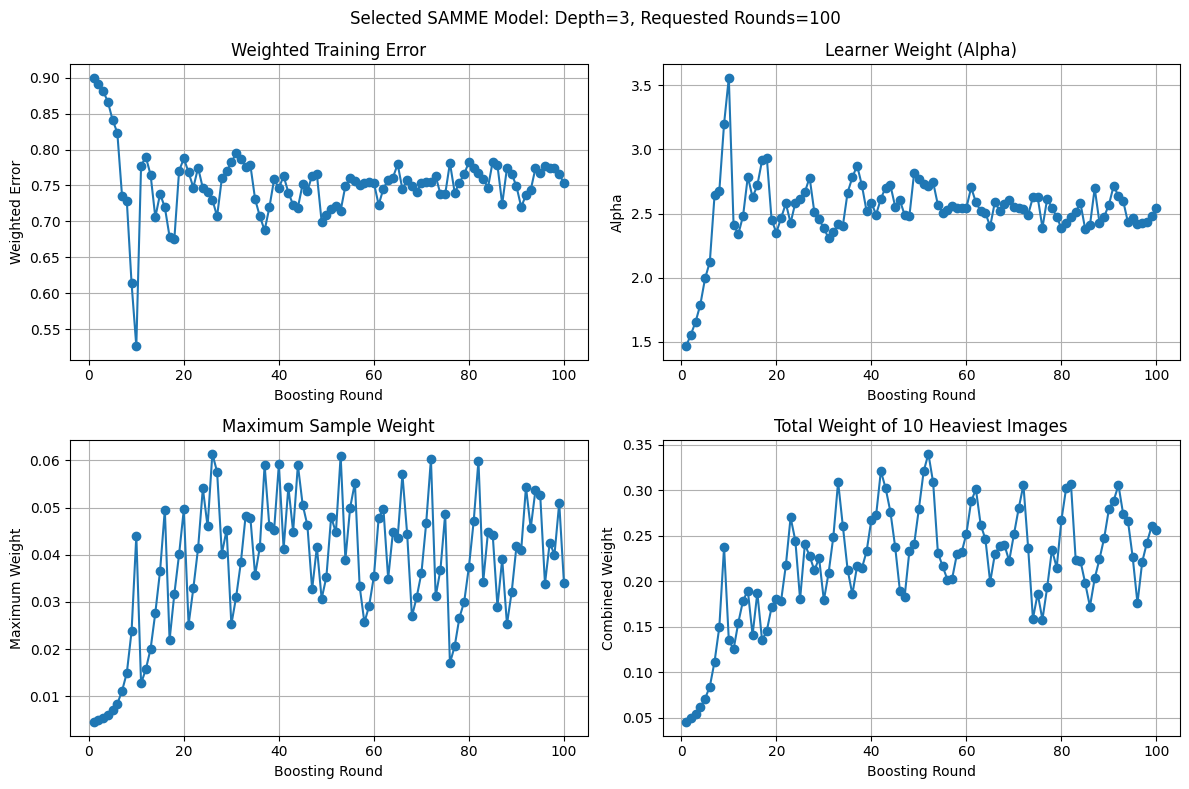

In [14]:
history = best_boost_model["history"]
rounds = np.arange(1, best_boost_model["actual_rounds"] + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(rounds, history["weighted_error"], marker="o")
axes[0, 0].set_title("Weighted Training Error")
axes[0, 0].set_xlabel("Boosting Round")
axes[0, 0].set_ylabel("Weighted Error")
axes[0, 0].grid(True)

axes[0, 1].plot(rounds, history["learner_weights"], marker="o")
axes[0, 1].set_title("Learner Weight (Alpha)")
axes[0, 1].set_xlabel("Boosting Round")
axes[0, 1].set_ylabel("Alpha")
axes[0, 1].grid(True)

axes[1, 0].plot(rounds, history["max_sample_weight"], marker="o")
axes[1, 0].set_title("Maximum Sample Weight")
axes[1, 0].set_xlabel("Boosting Round")
axes[1, 0].set_ylabel("Maximum Weight")
axes[1, 0].grid(True)

axes[1, 1].plot(rounds, history["top10_weight"], marker="o")
axes[1, 1].set_title("Total Weight of 10 Heaviest Images")
axes[1, 1].set_xlabel("Boosting Round")
axes[1, 1].set_ylabel("Combined Weight")
axes[1, 1].grid(True)

plt.suptitle(
    f"Selected SAMME Model: Depth={best_depth_boost}, "
    f"Requested Rounds={best_rounds_boost}"
)
plt.tight_layout()
plt.show()

In [15]:
# (Q-2).c
B_VALUES = [25, 50, 100]
RANDOM_SEED = 26016


# 1.bagging: train 100 tress n record time

rng = np.random.default_rng(RANDOM_SEED)
n_train = len(X_train)

bagged_trees = []
bagging_times = []
start_time = time.perf_counter()

for b in range(1, 101):
  bootstrap_indices = rng.choice(n_train, size = n_train, replace = True)

  tree = DecisionTreeClassifier(
      max_depth = None,
      min_samples_leaf = 4,
      random_state = RANDOM_SEED + b
  )

  tree.fit(
      X_train[bootstrap_indices],
      y_train[bootstrap_indices]
  )

  bagged_trees.append(tree)

  if b in B_VALUES:
    bagging_times.append(time.perf_counter() - start_time)





In [16]:
def predict_bagging(trees, X):

  all_predictions = np.array([
      tree.predict(X) for tree in trees
  ])

  predictions = []

  for i in range(all_predictions.shape[1]):

    labels, counts = np.unique(
        all_predictions[:, i], return_counts = True
    )

    predictions.append(labels[np.argmax(counts)])

  return np.array(predictions)


In [17]:
boosting_models = []
boosting_times = []

for rounds in B_VALUES:

  start_time = time.perf_counter()

  model = samme(
      X_train, y_train,
      X_val, y_val,
      max_depth = 3,
      n_rounds = rounds,
      seed = RANDOM_SEED
  )

  end_time = time.perf_counter() - start_time

  boosting_models.append(model)
  boosting_times.append(end_time)



In [18]:
results = []

for i, b in enumerate(B_VALUES):

  bagged_prefix = bagged_trees[:b]

  bag_train_pred = predict_bagging(bagged_prefix, X_train)
  bag_val_pred = predict_bagging(bagged_prefix, X_val)
  bag_test_pred = predict_bagging(bagged_prefix, X_test)

  results.append({
        "Method": "Bagging",
        "Learners": b,
        "Train accuracy": np.mean(bag_train_pred == y_train),
        "Validation accuracy": np.mean(bag_val_pred == y_val),
        "Clean test accuracy": np.mean(bag_test_pred == y_test),
        "Training time (sec)": bagging_times[i]
  })

  boost_model = boosting_models[i]

  boost_train_pred = pred_samme(boost_model, X_train)
  boost_val_pred = pred_samme(boost_model, X_val)
  boost_test_pred = pred_samme(boost_model, X_test)

  results.append({
        "Method": "SAMME Boosting",
        "Learners": b,
        "Train accuracy": np.mean(boost_train_pred == y_train),
        "Validation accuracy": np.mean(boost_val_pred == y_val),
        "Clean test accuracy": np.mean(boost_test_pred == y_test),
        "Training time (sec)": boosting_times[i]
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index = False))

        Method  Learners  Train accuracy  Validation accuracy  Clean test accuracy  Training time (sec)
       Bagging        25          1.0000               0.8000               0.8000              65.3940
SAMME Boosting        25          0.4750               0.2000               0.2625              13.7971
       Bagging        50          1.0000               0.8625               0.9000             138.8948
SAMME Boosting        50          0.4792               0.1750               0.2250              26.5988
       Bagging       100          1.0000               0.8625               0.9000             252.8261
SAMME Boosting       100          0.9500               0.3375               0.3875              54.4637


In [19]:
# print("X_train shape:", X_train.shape)
# print("y_train shape:", y_train.shape)

# print("Final weights shape:", np.array(final_weights).shape)

# print("Number of saved weight rounds:",
#       len(boost_model_100["history"]["sample_weights_by_round"]))

# print("First saved weight array shape:",
#       np.array(
#           boost_model_100["history"]["sample_weights_by_round"][0]
#       ).shape)

# print("First prediction array shape:",
#       np.array(
#           boost_model_100["history"]["training_predictions"][0]
#       ).shape)

In [20]:
boost_model_100 = samme(
    X_train, y_train,
    X_val, y_val,
    max_depth = 3,
    n_rounds = 100,
    seed = RANDOM_SEED
)

final_weights = boost_model_100["history"]["sample_weights_by_round"][-1]


# indx of training sample with the largest weight

hard_idx = np.argmax(final_weights)

print("Training position:", hard_idx)
print("True identity:", y_train[hard_idx])
print("Final sample weight:", final_weights[hard_idx])

# weight n pred history for this img
weight_history = np.array([
    weights[hard_idx]
    for weights in boost_model_100["history"][
        "sample_weights_by_round"
    ]
])

prediction_history = np.array([
    predictions[hard_idx]
    for predictions in boost_model_100["history"][
        "training_predictions"
    ]
])

print("Predictions across rounds:")
print(prediction_history)

print("Weight history:")
print(weight_history)

Training position: 56
True identity: 9
Final sample weight: 0.03393790347954122
Predictions across rounds:
[ 0  1  2  3  4  9 36 14 16  9  1  2  3  4 15 25 14 16 20 39 12  3  4 22
  9 25 16 24 20 34  3  2  4 39 22  9 36 20 16  3  8  4 39 22  9 30  0 20
  2  3  4 39 28 12  9  0 18 16 30 20  4 39 28 12  9  7 22 16 30  3  2  4
 28  9 15 34 20 37 30  3 22  4 23 12 14 34 39 20 37  2  9  4 28 14 12 15
 22 16 25  2]
Weight history:
[0.00451389 0.00493575 0.00545902 0.00613974 0.00711491 0.00100791
 0.00133709 0.0017896  0.0028422  0.00014994 0.00018803 0.00023213
 0.00029586 0.00040869 0.00053973 0.00073122 0.00105031 0.00151705
 0.00191993 0.00237647 0.00301573 0.00393569 0.00495224 0.00646986
 0.00062313 0.00083184 0.00114683 0.00147146 0.00186405 0.00232376
 0.00285056 0.00352966 0.0044342  0.00555335 0.00740832 0.00063208
 0.00089637 0.0012149  0.00156132 0.00203987 0.00260577 0.0034329
 0.00462877 0.00627422 0.0006318  0.00082972 0.00105908 0.00134884
 0.00188019 0.00258486 0.00351549 0.

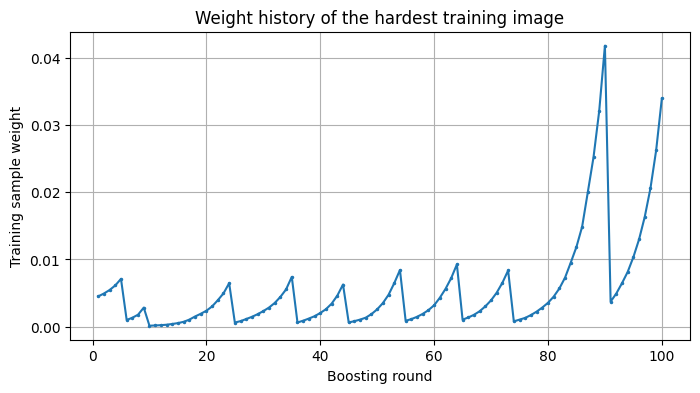

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(weight_history) + 1),
    weight_history,
    marker=".",
    markersize=3
)
plt.xlabel("Boosting round")
plt.ylabel("Training sample weight")
plt.title("Weight history of the hardest training image")
plt.grid(True)
plt.show()

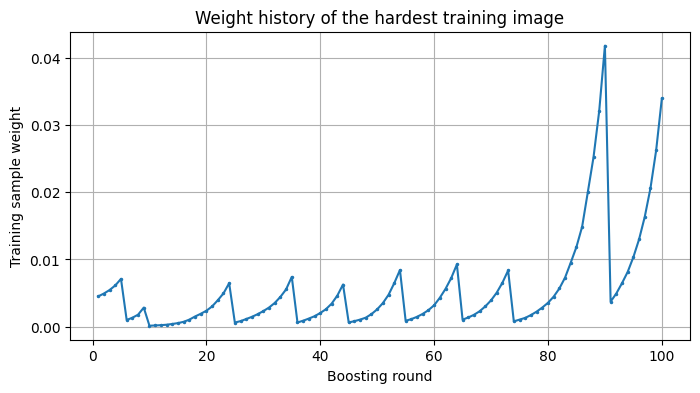

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(weight_history) + 1),
    weight_history,
    marker=".",
    markersize=3
)
plt.xlabel("Boosting round")
plt.ylabel("Training sample weight")
plt.title("Weight history of the hardest training image")
plt.grid(True)
plt.show()

In [51]:
# (Q-2).d

# frozen settings from q1 n q2

TREE_DEPTH = None
MIN_SAMPLES_LEAF = 4
B_FINAL = 50

X_test_clean = X_test.copy()

X_test_masked = X_test.reshape(-1, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked.reshape(len(X_test), -1)

In [52]:
# train frozen single tree

single_tree = DecisionTreeClassifier(
    max_depth=TREE_DEPTH,
    min_samples_leaf=MIN_SAMPLES_LEAF,
    random_state=seed
)

single_tree.fit(X_train, y_train)


DecisionTreeClassifier(min_samples_leaf=4, random_state=26016)

In [53]:
# bagging using bootstrap samples as q1

bootstrap_rng = np.random.default_rng(seed)

final_bagged_trees = []

for b in range(B_FINAL):

  bootstrap_indices = bootstrap_rng.choice(
      len(X_train),
      size = len(X_train),
      replace = True
  )

  tree = DecisionTreeClassifier(
      max_depth = TREE_DEPTH,
      min_samples_leaf = MIN_SAMPLES_LEAF,
      random_state = seed + b
  )

  tree.fit(
        X_train[bootstrap_indices],
        y_train[bootstrap_indices]
    )

  final_bagged_trees.append(tree)

In [54]:
classes = np.unique(y_train)

def bagging_predict(model_trees, X_eval):
    final_predictions = []
    confidence = []
    all_vote_counts = []

    for x in X_eval:
        # Each tree predicts the class of this one image
        predictions = np.array([
            tree.predict(x.reshape(1, -1))[0]
            for tree in model_trees
        ])

        # Count votes across all trees
        votes = np.bincount(
            predictions.astype(int),
            minlength=40
        )

        final_predictions.append(np.argmax(votes))
        confidence.append(np.max(votes) / len(model_trees))
        all_vote_counts.append(votes)

    return (
        np.array(final_predictions),
        np.array(confidence),
        np.array(all_vote_counts)
    )

In [55]:
def boosting_scores(model, X_eval):
    # SAMME weighted class scores
    scores = np.zeros((len(X_eval), len(model["classes"])))

    for tree, alpha in zip(
        model["learners"],
        model["learner_weights"]
    ):
        predictions = tree.predict(X_eval)

        for j, class_label in enumerate(model["classes"]):
            scores[:, j] += alpha * (predictions == class_label)

    total_alpha = np.sum(model["learner_weights"])

    if total_alpha > 0:
        normalized_scores = scores / total_alpha
    else:
        normalized_scores = np.zeros_like(scores)

    best_positions = np.argmax(normalized_scores, axis=1)

    predictions = model["classes"][best_positions]
    confidence = np.max(normalized_scores, axis=1)

    return predictions, confidence, normalized_scores

In [56]:
def pairwise_disagreement(predictions):
    n = len(predictions)

    if n < 2:
        return 0.0

    _, counts = np.unique(predictions, return_counts=True)

    agreeing_pairs = np.sum(counts * (counts - 1)) / 2
    total_pairs = n * (n - 1) / 2

    return 1 - agreeing_pairs / total_pairs

In [57]:
# evaluate all three modell on both test sets
def evaluate_q2d(X_eval, y_true, dataset_name):

    # Single tree
    tree_pred = single_tree.predict(X_eval)
    tree_prob = single_tree.predict_proba(X_eval)
    tree_conf = np.max(tree_prob, axis=1)

    # Bagging
    bag_pred, bag_conf, bag_votes = bagging_predict(
        final_bagged_trees, X_eval
    )

    # Boosting
    boost_pred, boost_conf, boost_scores = boosting_scores(
        best_boost_model, X_eval
    )

    results = [
        {
            "Dataset": dataset_name,
            "Model": "Single Tree",
            "Accuracy": np.mean(tree_pred == y_true),
            "Mean Confidence": np.mean(tree_conf)
        },
        {
            "Dataset": dataset_name,
            "Model": "Bagging (50 trees)",
            "Accuracy": np.mean(bag_pred == y_true),
            "Mean Confidence": np.mean(bag_conf)
        },
        {
            "Dataset": dataset_name,
            "Model": "SAMME Boosting",
            "Accuracy": np.mean(boost_pred == y_true),
            "Mean Confidence": np.mean(boost_conf)
        }
    ]

    predictions = {
        "tree": tree_pred,
        "tree_conf": tree_conf,
        "bag": bag_pred,
        "bag_conf": bag_conf,
        "bag_votes": bag_votes,
        "boost": boost_pred,
        "boost_conf": boost_conf,
        "boost_scores": boost_scores
    }

    return results, predictions


In [58]:
clean_results, clean_pred = evaluate_q2d(
    X_test_clean, y_test, "Clean"
)

masked_results, masked_pred = evaluate_q2d(
    X_test_masked, y_test, "Masked"
)

results_df = pd.DataFrame(clean_results + masked_results)

print("Q2(d): CLEAN AND MASKED TEST RESULTS")
print(results_df.to_string(index=False, formatters={
    "Accuracy": "{:.4f}".format,
    "Mean Confidence": "{:.4f}".format
}))

Q2(d): CLEAN AND MASKED TEST RESULTS
Dataset              Model Accuracy Mean Confidence
  Clean        Single Tree   0.5625          0.9815
  Clean Bagging (50 trees)   0.9000          0.3910
  Clean     SAMME Boosting   0.3875          0.1000
 Masked        Single Tree   0.2750          1.0000
 Masked Bagging (50 trees)   0.7375          0.2923
 Masked     SAMME Boosting   0.3875          0.0979


In [59]:

# Find a test face where bagging and boosting respond differently

bag_changed = clean_pred["bag"] != masked_pred["bag"]
boost_changed = clean_pred["boost"] != masked_pred["boost"]

different_predictions = (
    masked_pred["bag"] != masked_pred["boost"]
)

candidates = np.where(
    different_predictions & (bag_changed | boost_changed)
)[0]

# Prefer a face where at least one model is wrong after masking
informative = [
    j for j in candidates
    if (
        masked_pred["bag"][j] != y_test[j]
        or masked_pred["boost"][j] != y_test[j]
    )
]

if len(informative) > 0:
    chosen = informative[0]
elif len(candidates) > 0:
    chosen = candidates[0]
else:
    chosen = None

if chosen is None:
    print("No suitable face found.")
else:
    print("Selected test face index:", chosen)
    print("True label:", y_test[chosen])
    print("Bagging prediction:", masked_pred["bag"][chosen])
    print("Boosting prediction:", masked_pred["boost"][chosen])


Selected test face index: 4
True label: 2
Bagging prediction: 33
Boosting prediction: 20


In [60]:
# reconstruct boosting sample weights(use same updated rule )
weights = np.ones(len(X_train)) / len(X_train)

for learner, alpha in zip(
    best_boost_model["learners"],
    best_boost_model["learner_weights"]
):
    train_predictions = learner.predict(X_train)
    wrong = train_predictions != y_train

    weights[wrong] *= np.exp(alpha)
    weights /= np.sum(weights)

top_indices = np.argsort(weights)[-10:][::-1]

print("\nTOP 10 TRAINING IMAGES BY FINAL BOOSTING WEIGHT")
print("Index = original Olivetti dataset image index")

weight_df = pd.DataFrame({
    "Original image index": train_indices[top_indices],
    "Identity": y_train[top_indices],
    "Final boosting weight": weights[top_indices]
})

print(weight_df.to_string(index=False, formatters={
    "Final boosting weight": "{:.6f}".format
}))



TOP 10 TRAINING IMAGES BY FINAL BOOSTING WEIGHT
Index = original Olivetti dataset image index
 Original image index  Identity Final boosting weight
                   95         9              0.033938
                  393        39              0.029510
                  204        20              0.027987
                  234        23              0.027801
                   88         8              0.026709
                   87         8              0.024352
                  107        10              0.022240
                  191        19              0.021401
                  193        19              0.021401
                  331        33              0.021376


Bagging pairwise disagreement: 0.9289795918367347
Boosting alpha-weighted disagreement: 0.9058616472114175

SELECTED TEST FACE
------------------
Test-set position: 4
Original dataset image index: 21
True identity: 2

Single tree:
Clean prediction: 2
Masked prediction: 35
Masked confidence: 1.0

Bagging:
Clean prediction: 2
Masked prediction: 33
Masked confidence: 0.16
Masked vote counts: {2: 7, 3: 2, 6: 1, 9: 2, 12: 5, 13: 3, 14: 3, 16: 1, 20: 3, 22: 1, 24: 1, 25: 5, 28: 2, 33: 8, 34: 1, 35: 4, 38: 1}
Fraction of trees disagreeing with winner: 0.9289795918367347

SAMME boosting:
Clean prediction: 4
Masked prediction: 20
Masked confidence: 0.09413835278858261
Masked normalized weighted class scores: {np.int64(0): np.float64(0.0058), np.int64(1): np.float64(0.0157), np.int64(2): np.float64(0.087), np.int64(3): np.float64(0.0681), np.int64(4): np.float64(0.0893), np.int64(5): np.float64(0.0), np.int64(6): np.float64(0.0), np.int64(7): np.float64(0.0), np.int64(8): np.float64(0.0409), np.

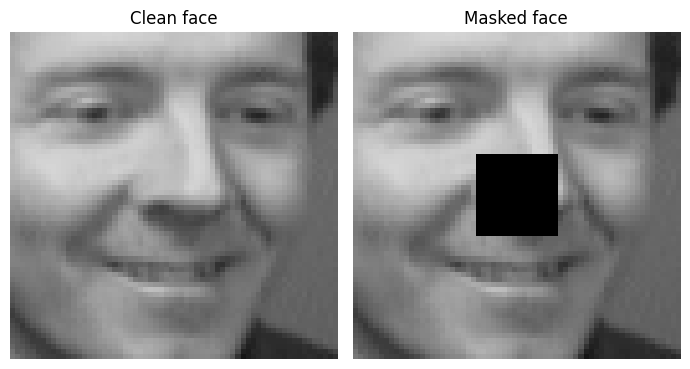

In [61]:
# display diff test face n model details

if chosen is None:

    print(
        "\nNo test face has different masked predictions "
        "between bagging and boosting."
    )

else:

    i = chosen

    # Predictions from individual bagging trees on this face
    votes = masked_pred["bag_votes"][i]
    vote_dict = {
        int(c): int(votes[c])
        for c in range(len(votes))
        if votes[c] > 0
    }

    individual_votes = np.array([
        tree.predict(X_test_masked[i:i+1])[0]
        for tree in final_bagged_trees
    ])

    disagreement = pairwise_disagreement(individual_votes)

    print("Bagging pairwise disagreement:", disagreement)

    # Boosting learner predictions on the same masked face
    boost_learner_predictions = np.array([
        learner.predict(X_test_masked[i:i+1])[0]
        for learner in best_boost_model["learners"]
    ])

    alphas = np.asarray(best_boost_model["learner_weights"])

    total_alpha = np.sum(alphas)

    disagreeing = (
        boost_learner_predictions != masked_pred["boost"][i]
    )

    weighted_boost_disagreement = (
        np.sum(alphas[disagreeing]) / total_alpha
        if total_alpha > 0 else np.nan
    )

    print(
        "Boosting alpha-weighted disagreement:",
        weighted_boost_disagreement
    )

    boost_learner_disagreement = np.mean(
        boost_learner_predictions != masked_pred["boost"][i]
    )

    print("\nSELECTED TEST FACE")
    print("------------------")
    print("Test-set position:", i)
    print("Original dataset image index:", test_indices[i])
    print("True identity:", y_test[i])

    print("\nSingle tree:")
    print("Clean prediction:", tree_clean[i])
    print("Masked prediction:", tree_mask[i])
    print("Masked confidence:", masked_pred["tree_conf"][i])

    print("\nBagging:")
    print("Clean prediction:", bag_clean[i])
    print("Masked prediction:", bag_mask[i])
    print("Masked confidence:", masked_pred["bag_conf"][i])
    print("Masked vote counts:", vote_dict)
    print("Fraction of trees disagreeing with winner:", disagreement)

    print("\nSAMME boosting:")
    print("Clean prediction:", boost_clean[i])
    print("Masked prediction:", boost_mask[i])
    print("Masked confidence:", masked_pred["boost_conf"][i])
    print(
        "Masked normalized weighted class scores:",
        dict(zip(
            best_boost_model["classes"].astype(int),
            np.round(masked_pred["boost_scores"][i], 4)
        ))
    )
    print(
        "Fraction of boosting learners disagreeing with winner:",
        boost_learner_disagreement
    )

    # Show the clean and masked versions of the same face
    fig, axes = plt.subplots(1, 2, figsize=(7, 4))

    axes[0].imshow(
        X_test_clean[i].reshape(64, 64),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0].set_title("Clean face")

    axes[1].imshow(
        X_test_masked[i].reshape(64, 64),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Masked face")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
